# Immuno Compass · Notebook 02: Define the target and clean the data (Day 2)

**Goal:** turn the raw tables into **one clean table with one row per patient group (cohort)**:
the target (n tested, y ADA-positive) plus tidy clues (features) about the study and the drug.

**Finish line:** `data/processed/cohorts.csv` is saved, and we can say exactly how many rows we kept, how many we dropped, and why.

> 🧒 *Simple version:* yesterday we opened the boxes. Today we wash the vegetables, throw away the rotten ones,
> and put everything on one tidy chopping board.

### Decisions made today (and why)
| # | Decision | Why |
|---|---|---|
| 1 | Use only **"Therapeutic Exposed"** rows for the target | In IDC, "Therapeutic Naive" rows are mostly the *before-treatment* (baseline) measurement: pooled ADA 4 % vs 15.5 % after treatment. ADAs measured before dosing are not caused by the drug. |
| 2 | **One row per cohort**, kept at the timepoint with the **highest** ADA frequency | The same patients are measured at several timepoints; counting each row would count the same people many times. "Peak ADA" matches the IDC's own `cohort_ADA` summary. A **"latest timepoint"** version is built too, as a sensitivity check. |
| 3 | Compute frequency as **y / n**, not the reported % column | 110 rows disagree by more than 1 percentage point; our model uses y and n directly. |
| 4 | **Flag**, don't drop, arms that mention placebo | Most such arms switch to the real drug later (e.g. "placebo to secukinumab"). |
| 5 | Extract a **numeric dose** from free text where possible | There is no dose column; dose is written in sentences. |

## 0 · Setup

In [1]:
import re, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)
pd.set_option("display.max_columns", 80); pd.set_option("display.max_colwidth", 80)

CANDIDATES = [Path("data/raw"), Path("../data/raw"), Path("/content/immuno-compass/data/raw"), Path("/content/data/raw")]
DATA_DIR = next((p for p in CANDIDATES if (p / "clinical_trials.csv").exists()), None)
if DATA_DIR is None and "google.colab" in sys.modules:
    from google.colab import files
    DATA_DIR = Path("/content/data/raw"); DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Please upload clinical_trials.csv and therapeutics.csv")
    for name, content in files.upload().items():
        (DATA_DIR / name).write_bytes(content)
assert DATA_DIR is not None, "Could not find data/raw/"
OUT_DIR = DATA_DIR.parent / "processed"; OUT_DIR.mkdir(exist_ok=True)

trials = pd.read_csv(DATA_DIR / "clinical_trials.csv", low_memory=False)
thera  = pd.read_csv(DATA_DIR / "therapeutics.csv")
print("trials:", trials.shape, "| therapeutics:", thera.shape)

# A running log of how many rows survive each step (we'll show it at the end).
log = [("raw rows", len(trials))]

trials: (3334, 43) | therapeutics: (218, 24)


## 1 · Target columns: n and y

* **n** = `Number of Patients analyzed for ADA` (patients tested)
* **y** = `Number of ADA+ patients` (patients who made ADAs)

In [2]:
df = trials.copy()
df["n_raw"] = pd.to_numeric(df["Number of Patients analyzed for ADA"], errors="coerce")
df["y_raw"] = pd.to_numeric(df["Number of ADA+ patients"], errors="coerce")

# A handful of rows have non-whole y (e.g. 41.76): they were back-calculated from a percentage.
# Patients come in whole numbers, so we round them and keep a flag.
ok = df["n_raw"].notna() & df["y_raw"].notna() & (df["n_raw"] > 0) & (df["y_raw"] <= df["n_raw"])
print("rows missing n or y, or impossible:", int((~ok).sum()))
df = df[ok].copy()
df["y_was_rounded"] = ((df["y_raw"] % 1 != 0) | (df["n_raw"] % 1 != 0)).astype(int)
print("rows with non-whole counts (rounded):", int(df["y_was_rounded"].sum()))
df["n"] = df["n_raw"].round().astype(int)
df["y"] = df["y_raw"].round().astype(int)
df["ada_freq"] = df["y"] / df["n"]
log.append(("has valid n and y", len(df)))

rows missing n or y, or impossible: 53
rows with non-whole counts (rounded): 7


## 2 · Keep only after-treatment rows ("Therapeutic Exposed")

> 🧒 Checking for "catchers" *before* the medicine is given tells us nothing about the medicine.

In [3]:
# Fix the one 'Naïve' spelling so both spellings count as the same thing.
df["exposure"] = df["Therapeutic Exposure Status"].str.replace("ï", "i", regex=False)

summary = (df.groupby("exposure")
             .apply(lambda g: pd.Series({"rows": len(g), "pooled_ADA": g["y"].sum() / g["n"].sum()}), include_groups=False))
display(summary.style.format({"rows": "{:.0f}", "pooled_ADA": "{:.1%}"}))

df = df[df["exposure"] == "Therapeutic Exposed"].copy()
log.append(("after-treatment rows only", len(df)))

,rows,pooled_ADA
exposure,,
Therapeutic Exposed,2653,15.5%
Therapeutic Naive,628,3.9%


## 3 · One row per patient group (cohort)

A **cohort** = one drug × one trial × one arm. The arm code is inside `IDC Row identifier`
(e.g. `CT0001_A1_002` → arm `A1`, timepoint row `002`).

In [4]:
THERA_KEY = "Therapeutic Assessed for ADA ID"
df["arm"] = df["IDC Row identifier"].str.split("_").str[1]
df["cohort_id"] = df[THERA_KEY] + "_" + df["Trial ID"] + "_" + df["arm"]
df["followup_days"] = pd.to_numeric(df["Immunogenicity Assessment Reported Up To (Days)"], errors="coerce")
df["row_order"] = np.arange(len(df))

rows_per_cohort = df.groupby("cohort_id").size()
print("cohorts:", len(rows_per_cohort), "| cohorts with >1 timepoint:", int((rows_per_cohort > 1).sum()),
      "| max timepoints in one cohort:", rows_per_cohort.max())

# MAIN rule: peak ADA frequency; if tied, prefer the timepoint with more patients tested.
peak = (df.sort_values(["cohort_id", "ada_freq", "n"], ascending=[True, False, False])
          .drop_duplicates("cohort_id"))

# SENSITIVITY rule: latest timepoint (longest follow-up); ties broken by the later row.
latest = (df.sort_values(["cohort_id", "followup_days", "row_order"], ascending=[True, False, False], na_position="first")
            .drop_duplicates("cohort_id"))

for name, t in [("peak", peak), ("latest", latest)]:
    print(f"{name:6s}: {len(t)} cohorts | pooled ADA {t['y'].sum()/t['n'].sum():.1%} | mean of row ADA {t['ada_freq'].mean():.1%}")
log.append(("one row per cohort (peak timepoint)", len(peak)))

cohorts: 1754 | cohorts with >1 timepoint: 324 | max timepoints in one cohort: 36
peak  : 1754 cohorts | pooled ADA 12.9% | mean of row ADA 12.9%
latest: 1754 cohorts | pooled ADA 12.2% | mean of row ADA 12.3%


⚠️ **Pitfall: picking the peak is slightly optimistic.** If a cohort has many timepoints, the highest one is partly
high by chance (especially with small n). That's why we keep the *latest* version and will re-run the main model on it.

## 4 · Clean the study-level clues

| Feature | Meaning (plain words) |
|---|---|
| `route` | How the drug enters the body: vein (IV), under the skin (SC), eye, muscle |
| `indication` | Disease area (cancer, autoimmune, …) |
| `blinding`, `randomized`, `comparator`, `design` | How the study was run |
| `start_year` | When the study began (assays got more sensitive over time) |
| `log_followup_days` | How long patients were watched for ADAs |
| `co_immunosuppressant` | Given together with immune-calming drugs (e.g. methotrexate), known to lower ADAs |
| `co_any_drug` | Any other drug given together |
| `arm_mentions_placebo` | Arm description mentions placebo |
| `log_dose_mgkg` | Dose converted to mg per kg of body weight (see section 5) |

In [5]:
def clean_study(t):
    t = t.copy()
    # Route: keep the 4 real routes; the 2 odd rows become "Other".
    t["route"] = t["Therapeutic Route of Administration"].where(
        t["Therapeutic Route of Administration"].isin(["Intravenous", "Subcutaneous", "Ophthalmic", "Intramuscular"]), "Other")
    # Indication: fix the database's own typo.
    t["indication"] = t["Disease Indication Category"].replace({"Metobolic and endocrine disorders": "Metabolic and endocrine disorders"})
    t["blinding"]   = t["Trial Blinding Type"].fillna("Unknown")
    t["randomized"] = t["Randomized or Not Randomized"].fillna("Unknown")
    t["comparator"] = t["Therapeutic Comparator"].fillna("Unknown")
    t["design"]     = t["Prospective or Retrospective"].fillna("Unknown")
    t["source"]     = t["Trial External Source"]
    t["audited"]    = t["Manually Audited"].astype(str).str.lower().eq("true").astype(int)
    t["start_year"] = pd.to_numeric(t["Trial Start Date"].astype(str).str[:4], errors="coerce")
    t["log_followup_days"] = np.log1p(t["followup_days"])

    # Co-administered drugs: blank means none were listed.
    co = t["Co-administered drugs"].fillna("").str.lower()
    IMMUNOSUPP = r"methotrexate|\bmtx\b|azathioprine|\baza\b|mercaptopurine|6-mp|cyclophosphamide|prednis|methylpred|dexameth|" \
                 r"hydrocortisone|steroid|mycophenol|leflunomide|cyclosporin|ciclosporin|tacrolimus|sirolimus|\bchop\b|\bcvp\b"
    t["co_any_drug"] = (co.str.strip() != "").astype(int)
    t["co_immunosuppressant"] = co.str.contains(IMMUNOSUPP, regex=True).astype(int)
    t["arm_mentions_placebo"] = t["Trial Arm Description"].str.lower().str.contains(r"placebo|\bpbo\b|sham", regex=True).astype(int)
    return t

peak, latest = clean_study(peak), clean_study(latest)
for c in ["route", "indication", "blinding", "randomized", "comparator", "design"]:
    print(f"\n--- {c} ---"); print(peak[c].value_counts().to_string())
print("\nco_immunosuppressant:", peak["co_immunosuppressant"].sum(), "| co_any_drug:", peak["co_any_drug"].sum(),
      "| arm_mentions_placebo:", peak["arm_mentions_placebo"].sum())


--- route ---
route
Intravenous      1082
Subcutaneous      639
Ophthalmic         20
Intramuscular      12
Other               1

--- indication ---
indication
Cancer and neoplasms                     797
Inflammation and autoimmunity            577
Neurological                             109
Cardiovascular                            75
Musculoskeletal                           53
Healthy Volunteer                         47
Unspecified                               26
Infectious diseases                       19
Blood Disorders                           13
Non-inflammatory respiratory diseases     12
Renal and urogenital                      12
Metabolic and endocrine disorders          7
Non-inflammatory skin diseases             7

--- blinding ---
blinding
Open Label    872
Double        623
Unknown       185
Triple         62
Single         12

--- randomized ---
randomized
Randomized        1014
Not Randomized     383
Unknown            357

--- comparator ---
comparator
Paral

## 5 · Dose: from sentences to a number

Dose text looks like *"8 mg/kg loading dose then 6 mg/kg every 3 weeks"* or *"sarilumab 150 mg sc q2w"*.
We take the **first dose mentioned** and convert it to **mg per kg** of body weight:

| Written as | Conversion (assumption, stated in the report) |
|---|---|
| mg/kg | as is |
| µg/kg | ÷ 1000 |
| mg/m² (body surface) | × 1.8 m² ÷ 70 kg |
| flat mg (or g) | ÷ 70 kg (typical adult) |

These are rough. That's why we also keep `dose_type` (how the dose was written) and a `dose_missing` flag.

In [6]:
UNIT = r"(mg/kg|mg/ kg|mg per kg|µg/kg|μg/kg|ug/kg|mcg/kg|mg/m2|mg/m²|mg/m\^2|mg|milligrams?|g)\b"
DOSE_RE = re.compile(r"(\d+(?:[.,]\d+)?)\s*" + UNIT, flags=re.IGNORECASE)

def parse_dose(text, drug=""):
    """Return (dose in mg/kg, dose_type) from a dosing sentence, else (nan, 'Unknown').
    Sentences often mention other drugs too ("epacadostat 100 mg + durvalumab 1500 mg"), so we first
    look for a dose written AFTER our drug's name, and only then fall back to the first dose in the text."""
    if not isinstance(text, str):
        return np.nan, "Unknown"
    m = None
    name = str(drug).split()[0].lower() if isinstance(drug, str) and drug.strip() else ""
    pos = text.lower().find(name) if name else -1
    if pos >= 0:
        m = DOSE_RE.search(text, pos)
    if m is None:
        m = DOSE_RE.search(text)
    if not m:
        return np.nan, "Unknown"
    value = float(m.group(1).replace(",", "."))
    unit = m.group(2).lower().replace(" ", "").replace("μ", "µ")
    if unit in ("mg/kg", "mgperkg"):          return value, "per kg"
    if unit in ("µg/kg", "ug/kg", "mcg/kg"):  return value / 1000, "per kg"
    if unit.startswith("mg/m"):               return value * 1.8 / 70, "per m2"
    if unit == "g":                           return value * 1000 / 70, "flat"
    return value / 70, "flat"                 # mg / milligram(s)

def add_dose(t):
    t = t.copy()
    drug   = t["Molecule Assessed for ADA INN Name"]
    first  = [parse_dose(x, d) for x, d in zip(t["Dosing Description"], drug)]
    second = [parse_dose(x, d) for x, d in zip(t["Therapeutic Dosing Schedule Description"], drug)]   # fallback text column
    t["dose_mgkg"] = [a[0] if not np.isnan(a[0]) else b[0] for a, b in zip(first, second)]
    t["dose_type"] = [a[1] if not np.isnan(a[0]) else b[1] for a, b in zip(first, second)]
    t.loc[t["dose_mgkg"] > 200, ["dose_mgkg", "dose_type"]] = [np.nan, "Unknown"]   # >200 mg/kg is a parsing error, not a dose
    t["dose_missing"] = t["dose_mgkg"].isna().astype(int)
    t["log_dose_mgkg"] = np.log1p(t["dose_mgkg"])
    return t

peak, latest = add_dose(peak), add_dose(latest)
print(f"cohorts with a dose: {1 - peak['dose_missing'].mean():.1%}")
print(peak["dose_type"].value_counts().to_string())
print("\nDose (mg/kg) summary:"); print(peak["dose_mgkg"].describe().round(3).to_string())
print("\nSpot-check 12 random parses — read them and make sure they look right:")
display(peak.loc[peak["dose_mgkg"].notna(), ["Molecule Assessed for ADA INN Name", "Dosing Description", "dose_mgkg", "dose_type"]].sample(12, random_state=1))

cohorts with a dose: 91.2%


dose_type
flat       1040
per kg      507
Unknown     154
per m2       53

Dose (mg/kg) summary:
count    1600.000
mean        5.478
std         6.313
min         0.000
25%         0.771
50%         3.000
75%        10.000
max        71.429

Spot-check 12 random parses — read them and make sure they look right:


,Molecule Assessed for ADA INN Name,Dosing Description,dose_mgkg,dose_type
3073,Trastuzumab emtansine,6 mg/kg or 8 mg/kg,6.000000,per kg
570,Tanezumab,"Participants were administered with tanezumab 10 mg iv infusion, once every ...",0.142857,flat
335,Denosumab,Participants received 180 mg denosumab by subcutaneous injection on day 1 an...,2.571429,flat
1941,Tanezumab,A single dose of tanezumab (rn624 or pf-04383119) 15 milligram (mg) intraven...,0.214286,flat
2917,Tremelimumab,"In part 1, participants with advanced, selected solid tumors were enrolled. ...",1.142857,flat
406,Rituximab,"Participants received rituximab, 1.0 g, iv, on days 1, 15, 168, and 182. par...",14.285714,flat
1663,Tralokinumab,Tralokinumab 400 mg q4w intravenously dosed for 24 weeks,5.714286,flat
1413,Avelumab,Participants with gastric (gc) and gastroesophageal junction cancer (gejc) w...,10.000000,per kg
2838,Hyaluronidase human,"Participants received daratumumab 1800 mg by sc injection on days 1, 8, 15 a...",25.714286,flat
377,Ranibizumab,In this extension study participants received ranibizumab intravitreal injec...,0.007143,flat


## 6 · Add the drug's ID card (therapeutics table)

| Feature | Meaning |
|---|---|
| `modality` | Kind of drug: antibody, enzyme, hormone, fusion protein … |
| `species` | Where the protein design came from: human, humanized, chimeric (part mouse), bacterial … |
| `backbone` | Antibody "skeleton" class (IgG1, IgG4 …) |
| `conjugate` | Is something attached (a toxin, PEG …)? |
| `expression` | What cells made it (hamster cells, mouse cells, bacteria …) |
| `light_chain`, `biosimilar` | Antibody light chain type; is it a copy of an existing drug |

In [7]:
def clean_thera(th):
    th = th.copy()
    norm = lambda s: s.astype(str).str.strip().str.lower()
    th["modality"]    = norm(th["Protein Modality"]).str.capitalize()
    th["species"]     = th["Species"].str.strip()
    th["backbone"]    = (norm(th["Antibody Backbone"]).str.replace("igg", "IgG", regex=False)
                         .str.replace("human", "Human", regex=False).str.replace("murine", "Murine", regex=False)
                         .replace({"not applicable": "Not applicable"}))
    th["conjugate"]   = norm(th["Conjugate Modification"]).str.capitalize()
    th["expression"]  = th["Expression System"].str.strip()
    th["light_chain"] = norm(th["Light Chain"]).str.capitalize()
    th["biosimilar"]  = th["Labelled as Biosimilar?"].eq("Yes").astype(int)
    keep = ["Therapeutic ID", "INN Name", "modality", "species", "backbone", "conjugate", "expression", "light_chain", "biosimilar"]
    return th[keep].rename(columns={"INN Name": "drug_name"})

th_clean = clean_thera(thera)
for c in ["modality", "species", "backbone", "conjugate", "expression", "light_chain"]:
    print(f"--- {c}: {th_clean[c].nunique()} values ---", dict(th_clean[c].value_counts()))

def join_thera(t):
    out = t.merge(th_clean, left_on=THERA_KEY, right_on="Therapeutic ID", how="left", validate="many_to_one")
    assert out["modality"].notna().all(), "some cohorts did not find their drug"
    return out

peak, latest = join_thera(peak), join_thera(latest)
print("\nall cohorts matched a drug ✔  | distinct drugs:", peak[THERA_KEY].nunique())

--- modality: 13 values --- {'Monoclonal antibody': np.int64(152), 'Hormone and growth factors': np.int64(14), 'Enzyme': np.int64(11), 'Antibody-drug conjugate': np.int64(9), 'Fc-fusion': np.int64(8), 'Immunotoxin': np.int64(6), 'Cytokine': np.int64(4), 'Blood clotting factors': np.int64(4), 'Single-domain antibody': np.int64(3), 'Antibody fragments': np.int64(2), 'Igg-like bispecific': np.int64(2), 'All other multispecifics': np.int64(2), 'Peptide': np.int64(1)}
--- species: 5 values --- {'Humanized': np.int64(98), 'Human': np.int64(84), 'Chimeric': np.int64(24), 'Bacterial': np.int64(10), 'Mouse': np.int64(2)}
--- backbone: 10 values --- {'Human IgG1': np.int64(125), 'Not applicable': np.int64(43), 'Human IgG4': np.int64(19), 'Human IgG2': np.int64(15), 'Human fab (ch1 IgG1)': np.int64(7), 'vhh': np.int64(3), 'scfv': np.int64(2), 'Human IgG2(ch1-hinge)/IgG4(ch2-ch3)': np.int64(2), 'Murine IgG1': np.int64(1), 'Murine IgG2': np.int64(1)}
--- conjugate: 6 values --- {'Unconjugated': np.

## 7 · Group rare categories into "Other"

Categories with fewer than **20 cohorts** are too small to learn from and slow down the Bayesian sampler.

In [8]:
CAT_COLS = ["route", "indication", "blinding", "randomized", "comparator", "design", "source",
            "dose_type", "modality", "species", "backbone", "conjugate", "expression", "light_chain"]
MIN_COUNT = 20

# Decide which levels to keep using the MAIN (peak) table, then apply the same mapping to both tables.
keep_levels = {c: set(peak[c].value_counts()[lambda s: s >= MIN_COUNT].index) for c in CAT_COLS}

def group_rare(t):
    t = t.copy()
    for c in CAT_COLS:
        t[c] = t[c].where(t[c].isin(keep_levels[c]), "Other")
    return t

peak, latest = group_rare(peak), group_rare(latest)
for c in CAT_COLS:
    print(f"{c:12s} → {sorted(peak[c].unique())}")

route        → ['Intravenous', 'Ophthalmic', 'Other', 'Subcutaneous']
indication   → ['Cancer and neoplasms', 'Cardiovascular', 'Healthy Volunteer', 'Inflammation and autoimmunity', 'Musculoskeletal', 'Neurological', 'Other', 'Unspecified']
blinding     → ['Double', 'Open Label', 'Other', 'Triple', 'Unknown']
randomized   → ['Not Randomized', 'Randomized', 'Unknown']
comparator   → ['Active controls', 'Parallel Assignment', 'Placebo/Sham', 'Unknown']
design       → ['Other', 'Prospective', 'Unknown']
source       → ['Clinicaltrials.gov', 'EU Clinical Trials Register', 'Journal Article', 'Other']
dose_type    → ['Unknown', 'flat', 'per kg', 'per m2']
modality     → ['Antibody-drug conjugate', 'Immunotoxin', 'Monoclonal antibody', 'Other']
species      → ['Bacterial', 'Chimeric', 'Human', 'Humanized', 'Other']
backbone     → ['Human IgG1', 'Human IgG2', 'Human IgG4', 'Not applicable', 'Other']
conjugate    → ['Drug conjugate', 'Not applicable', 'Other', 'Unconjugated']
expression   → ['C

## 8 · Missingness and correlation of the numeric features

In [9]:
NUM_COLS = ["log_dose_mgkg", "start_year", "log_followup_days"]
FLAG_COLS = ["co_immunosuppressant", "co_any_drug", "arm_mentions_placebo", "audited", "biosimilar", "dose_missing", "y_was_rounded"]

miss = peak[NUM_COLS].isna().mean().rename("share_missing").to_frame()
display(miss.style.format("{:.1%}"))
# Median imputation + missing-indicator will happen INSIDE each training fold (Day 4), not here,
# so the test fold never leaks into the median. We only record the indicators now.
for c in NUM_COLS:
    peak[c + "_missing"] = peak[c].isna().astype(int); latest[c + "_missing"] = latest[c].isna().astype(int)

print("Correlation between numeric features (|r| > 0.8 would mean one is redundant):")
display(peak[NUM_COLS].corr().round(2))

,share_missing
log_dose_mgkg,8.8%
start_year,0.8%
log_followup_days,2.6%


Correlation between numeric features (|r| > 0.8 would mean one is redundant):


,log_dose_mgkg,start_year,log_followup_days
log_dose_mgkg,1.00,0.22,0.21
start_year,0.22,1.00,0.02
log_followup_days,0.21,0.02,1.00


## 9 · Small-study check

cohorts with n < 10: 358 (20%) — they hold only 0.9% of patients
cohorts with n < 20: 567 (32%) — they hold only 2.3% of patients

We KEEP small cohorts; models weight each cohort by n, and we will re-run with n ≥ 20 as a sensitivity check.


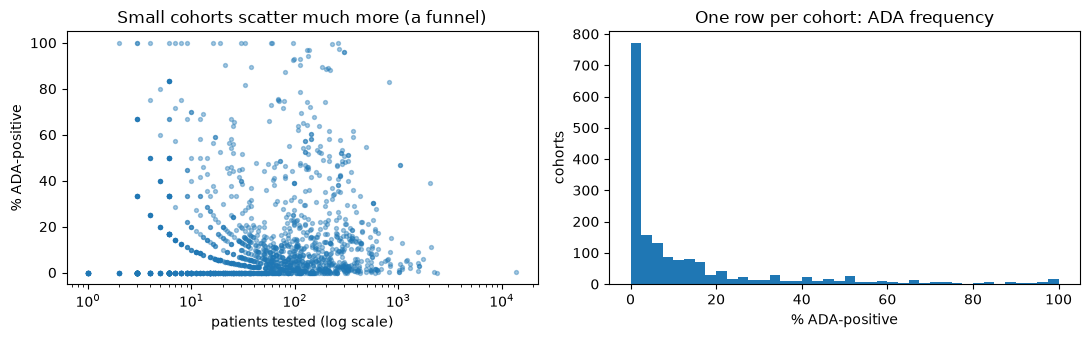

In [10]:
for cut in [10, 20]:
    small = peak["n"] < cut
    print(f"cohorts with n < {cut}: {small.sum()} ({small.mean():.0%}) — they hold only {peak.loc[small,'n'].sum()/peak['n'].sum():.1%} of patients")
print("\nWe KEEP small cohorts; models weight each cohort by n, and we will re-run with n ≥ 20 as a sensitivity check.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(peak["n"], peak["ada_freq"] * 100, s=8, alpha=0.4)
ax[0].set_xscale("log"); ax[0].set_xlabel("patients tested (log scale)"); ax[0].set_ylabel("% ADA-positive")
ax[0].set_title("Small cohorts scatter much more (a funnel)")
ax[1].hist(peak["ada_freq"] * 100, bins=40)
ax[1].set_xlabel("% ADA-positive"); ax[1].set_ylabel("cohorts"); ax[1].set_title("One row per cohort: ADA frequency")
plt.tight_layout(); plt.show()

## 10 · Save the clean tables

In [11]:
ID_COLS = ["cohort_id", THERA_KEY, "drug_name", "Trial ID", "arm", "Trial Arm Timepoint Description", "followup_days", "dose_mgkg"]
TARGET  = ["n", "y", "ada_freq"]
FEATURES_CAT = CAT_COLS
FEATURES_NUM = NUM_COLS + [c + "_missing" for c in NUM_COLS] + FLAG_COLS
cols = ID_COLS + TARGET + FEATURES_CAT + FEATURES_NUM

peak[cols].to_csv(OUT_DIR / "cohorts.csv", index=False)
latest[cols].to_csv(OUT_DIR / "cohorts_latest_timepoint.csv", index=False)
print("saved:", OUT_DIR / "cohorts.csv", peak[cols].shape)
print("saved:", OUT_DIR / "cohorts_latest_timepoint.csv", latest[cols].shape)

display(pd.DataFrame(log, columns=["step", "rows remaining"]))

saved: ../data/processed/cohorts.csv (1754, 38)
saved: ../data/processed/cohorts_latest_timepoint.csv (1754, 38)


,step,rows remaining
0,raw rows,3334
1,has valid n and y,3281
2,after-treatment rows only,2653
3,one row per cohort (peak timepoint),1754


## 11 · Day 2 findings (write-up)

* **Target:** y = ADA-positive patients, n = patients tested, frequency = y/n. Rows with missing or impossible counts were removed (53); a few back-calculated (non-whole) counts were rounded and flagged.
* **"Therapeutic Naive" rows are pre-treatment baselines** (pooled ADA ≈ 4 % vs ≈ 15 % after treatment), so they are excluded from the target.
* **Repeated measurements:** the same patients are measured at up to 36 timepoints. We keep **one row per cohort** (peak ADA timepoint) → **1,754 cohorts from 137 drugs**, and also save a **latest-timepoint** version for a sensitivity check.
* **Dose** had to be parsed from free text and converted to mg/kg with stated assumptions (70 kg adult, 1.8 m² body surface).
* **Co-administered immunosuppressants** (methotrexate, steroids, etc.) are captured as a feature; biologically they are expected to *lower* ADA.
* Rare categories (< 20 cohorts) are grouped into "Other". Numeric imputation is postponed to inside the CV folds to avoid leakage.

**Next (Day 3):** explore. Which routes, drug types and diseases have higher ADA? How skewed is the data toward a few drugs?